# Explainable Credit Risk Prediction System — Advanced Version (Google Colab)

This continues from the base notebook and adds everything needed to turn the project into
a resume-worthy, explainable ML system:

1. **XGBoost** added to the model comparison
2. **Class imbalance handling** — class weights + SMOTE, compared against the unweighted baseline
3. **Cross-validation** (5-fold, ROC-AUC)
4. **Hyperparameter tuning** (RandomizedSearchCV)
5. **Threshold optimization** (sweep + F1-maximizing threshold)
6. **SHAP explainability** — global + individual predictions
7. **Leak-free `Pipeline`** (preprocessing + SMOTE + model as one object)
8. Exports `pipeline.joblib` + `threshold.json` — the exact artifacts the FastAPI/Streamlit app expects

**Dataset:** [Default of Credit Card Clients (Kaggle)](https://www.kaggle.com/datasets/uciml/default-of-credit-card-clients-dataset)


## 0. Install extra libraries & load data

In [1]:
!pip install -q xgboost imbalanced-learn shap


In [3]:
from google.colab import files
import os

if not os.path.exists("UCI_Credit_Card.csv"):
    print("Upload your kaggle.json (Kaggle -> Settings -> API -> Create New Token)")
    uploaded = files.upload()
    if 'kaggle.json' in uploaded:
        os.makedirs('/root/.kaggle', exist_ok=True)
        os.rename('kaggle.json', '/root/.kaggle/kaggle.json')
        os.chmod('/root/.kaggle/kaggle.json', 0o600)
        !pip install -q kaggle
        !kaggle datasets download -d uciml/default-of-credit-card-clients-dataset
        !unzip -o default-of-credit-card-clients-dataset.zip
    else:
        print("Error: 'kaggle.json' was not uploaded. Please ensure you upload the correct file.")

## 1. Cleaning & feature engineering (same logic as the base notebook, as reusable functions)

In [4]:
import numpy as np
import pandas as pd

TARGET_COL = "default"
PAY_STATUS_COLS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]
CATEGORICAL_COLS = ["SEX", "EDUCATION", "MARRIAGE", "age_group", "limit_group"]


def clean_raw(df):
    df = df.copy()
    df = df.rename(columns={"default.payment.next.month": TARGET_COL})
    if "ID" in df.columns:
        df = df.drop(columns=["ID"])
    df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
    return df.drop_duplicates()


def engineer_features(df):
    df = df.copy()
    df["avg_bill_amt"] = df[BILL_COLS].mean(axis=1)
    df["avg_pay_amt"] = df[PAY_AMT_COLS].mean(axis=1)
    df["credit_utilization"] = (df["avg_bill_amt"] / df["LIMIT_BAL"]).clip(lower=0)
    df["debt_to_limit_ratio"] = (df["avg_bill_amt"] / df["LIMIT_BAL"]).replace([np.inf, -np.inf], 0).fillna(0)
    ratio = df["avg_pay_amt"] / df["avg_bill_amt"].replace(0, np.nan)
    df["payment_to_bill_ratio"] = ratio.replace([np.inf, -np.inf], np.nan).fillna(0)
    df["num_months_delayed"] = (df[PAY_STATUS_COLS] > 0).sum(axis=1)
    df["max_delay"] = df[PAY_STATUS_COLS].max(axis=1)
    df["age_group"] = pd.cut(df["AGE"], bins=[0, 25, 35, 45, 55, 200],
        labels=["age_under_25", "age_26_35", "age_36_45", "age_46_55", "age_56_plus"]).astype(str)
    df["limit_group"] = pd.cut(df["LIMIT_BAL"], bins=[-1, 50000, 150000, 300000, np.inf],
        labels=["low", "medium", "high", "very_high"]).astype(str)
    return df


df = pd.read_csv("UCI_Credit_Card.csv")
df = clean_raw(df)
df = engineer_features(df)

numeric_features = [c for c in df.columns if c not in CATEGORICAL_COLS + [TARGET_COL]]
categorical_features = [c for c in CATEGORICAL_COLS if c in df.columns]

print(df.shape)
df.head()


(29965, 33)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,default,avg_bill_amt,avg_pay_amt,credit_utilization,debt_to_limit_ratio,payment_to_bill_ratio,num_months_delayed,max_delay,age_group,limit_group
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,1,1284.000000,114.833333,0.064200,0.064200,0.089434,2,2,age_under_25,low
1,120000.0,2,2,2,26,-1,2,0,0,0,...,1,2846.166667,833.333333,0.023718,0.023718,0.292791,2,2,age_26_35,medium
2,90000.0,2,2,2,34,0,0,0,0,0,...,0,16942.166667,1836.333333,0.188246,0.188246,0.108388,0,0,age_26_35,medium
3,50000.0,2,2,1,37,0,0,0,0,0,...,0,38555.666667,1398.000000,0.771113,0.771113,0.036259,0,0,age_36_45,low
4,50000.0,1,2,1,57,-1,0,-1,0,0,...,0,18223.166667,9841.500000,0.364463,0.364463,0.540054,0,0,age_56_plus,low


In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print("Class balance in train:", y_train.value_counts(normalize=True).round(3).to_dict())


(23972, 32) (5993, 32)
Class balance in train: {0: 0.779, 1: 0.221}


## 2. Why isn't accuracy enough here?

The target is imbalanced (roughly 78% non-default / 22% default). A model that always predicts
"no default" would score ~78% accuracy while catching **zero** actual defaulters — useless for
a bank. That's why we track Precision/Recall/F1/ROC-AUC throughout, and why we handle the
imbalance explicitly below instead of ignoring it.


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def build_preprocessor(numeric_features, categorical_features):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])

preprocessor = build_preprocessor(numeric_features, categorical_features)


## 3. Model comparison: Logistic Regression → Decision Tree → Random Forest → XGBoost

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix, roc_curve)
from imblearn.pipeline import Pipeline as ImbPipeline

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, class_weight="balanced",
                                             random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                              scale_pos_weight=scale_pos_weight, eval_metric="logloss", random_state=42),
}

rows = []
fitted_pipelines = {}
for name, clf in candidates.items():
    pipe = ImbPipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    fitted_pipelines[name] = pipe
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, proba)})

comparison_df = pd.DataFrame(rows).set_index("Model").round(4)
comparison_df


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7462,0.4457,0.6041,0.5130,0.7545
Decision Tree,0.7532,0.4566,0.6071,0.5212,0.7537
Random Forest,0.7819,0.5063,0.5769,0.5393,0.7741
XGBoost,0.7586,0.4647,0.6011,0.5242,0.7687


## 4. Class imbalance: class weights vs. SMOTE

The models above already use `class_weight="balanced"`. Now compare against **SMOTE**
(synthetic oversampling of the minority class) inside the training fold only — SMOTE must
never touch the test set, or it leaks synthetic copies of test-like points into training.


In [8]:
from imblearn.over_sampling import SMOTE

xgb_smote_pipe = ImbPipeline([
    ("prep", preprocessor),
    ("smote", SMOTE(random_state=42)),
    ("clf", XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                           eval_metric="logloss", random_state=42)),
])
xgb_smote_pipe.fit(X_train, y_train)

proba_smote = xgb_smote_pipe.predict_proba(X_test)[:, 1]
pred_smote = xgb_smote_pipe.predict(X_test)

comparison_df.loc["XGBoost + SMOTE"] = {
    "Accuracy": accuracy_score(y_test, pred_smote),
    "Precision": precision_score(y_test, pred_smote),
    "Recall": recall_score(y_test, pred_smote),
    "F1": f1_score(y_test, pred_smote),
    "ROC-AUC": roc_auc_score(y_test, proba_smote),
}
comparison_df.round(4)


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.7462,0.4457,0.6041,0.5130,0.7545
Decision Tree,0.7532,0.4566,0.6071,0.5212,0.7537
Random Forest,0.7819,0.5063,0.5769,0.5393,0.7741
XGBoost,0.7586,0.4647,0.6011,0.5242,0.7687
XGBoost + SMOTE,0.8150,0.6322,0.3914,0.4835,0.7673


## 5. Cross-validation — is the ROC-AUC stable across folds?

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_smote_pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)

print(f"5-fold CV ROC-AUC: mean={cv_scores.mean():.4f}  std={cv_scores.std():.4f}")
print("Fold scores:", np.round(cv_scores, 4))


5-fold CV ROC-AUC: mean=0.7672  std=0.0054
Fold scores: [0.7725 0.7662 0.7625 0.7604 0.7743]


## 6. Hyperparameter tuning (RandomizedSearchCV)

In [10]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "clf__n_estimators": [200, 300, 400, 600],
    "clf__max_depth": [3, 4, 5, 6, 8],
    "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "clf__subsample": [0.7, 0.8, 0.9, 1.0],
    "clf__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "smote__k_neighbors": [3, 5, 7],
}

search = RandomizedSearchCV(
    xgb_smote_pipe, param_distributions=param_distributions, n_iter=25,
    scoring="roc_auc", cv=cv, n_jobs=-1, random_state=42, verbose=1,
)
search.fit(X_train, y_train)

best_pipeline = search.best_estimator_
print("Best params:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))


Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best params: {'smote__k_neighbors': 7, 'clf__subsample': 0.7, 'clf__n_estimators': 300, 'clf__max_depth': 6, 'clf__learning_rate': 0.01, 'clf__colsample_bytree': 0.9}
Best CV ROC-AUC: 0.7785


In [11]:
y_proba_final = best_pipeline.predict_proba(X_test)[:, 1]
y_pred_default_thresh = best_pipeline.predict(X_test)

print("Tuned model @ default 0.5 threshold:")
print(f"  Accuracy:  {accuracy_score(y_test, y_pred_default_thresh):.4f}")
print(f"  Precision: {precision_score(y_test, y_pred_default_thresh):.4f}")
print(f"  Recall:    {recall_score(y_test, y_pred_default_thresh):.4f}")
print(f"  F1:        {f1_score(y_test, y_pred_default_thresh):.4f}")
print(f"  ROC-AUC:   {roc_auc_score(y_test, y_proba_final):.4f}")


Tuned model @ default 0.5 threshold:
  Accuracy:  0.7964
  Precision: 0.5448
  Recall:    0.4857
  F1:        0.5136
  ROC-AUC:   0.7684


## 7. Threshold optimization

`model.predict()` silently uses 0.5. For credit risk, the business question is usually:
*"how many risky customers can we afford to miss (false negatives) vs. how many good
customers can we afford to flag (false positives)?"* We sweep thresholds and pick the one
that maximizes F1 here — swap in a recall- or precision-driven objective if the business
gives you one.


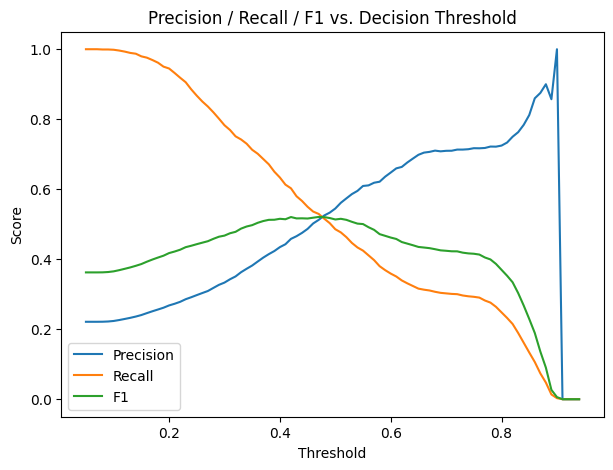

Best threshold by F1: {'threshold': 0.47, 'precision': 0.5124087591240876, 'recall': 0.5294117647058824, 'f1': 0.5207715133531158}


In [12]:
thresholds = np.arange(0.05, 0.95, 0.01)
sweep = []
for t in thresholds:
    pred = (y_proba_final >= t).astype(int)
    sweep.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
sweep_df = pd.DataFrame(sweep)

import matplotlib.pyplot as plt
plt.figure(figsize=(7,5))
plt.plot(sweep_df["threshold"], sweep_df["precision"], label="Precision")
plt.plot(sweep_df["threshold"], sweep_df["recall"], label="Recall")
plt.plot(sweep_df["threshold"], sweep_df["f1"], label="F1")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs. Decision Threshold")
plt.legend()
plt.show()

best_row = sweep_df.loc[sweep_df["f1"].idxmax()]
best_threshold = float(best_row["threshold"])
print("Best threshold by F1:", best_row.to_dict())


Final tuned model @ optimized threshold (0.47):
  Accuracy:  0.7844
  Precision: 0.5124
  Recall:    0.5294
  F1:        0.5208
  ROC-AUC:   0.7684


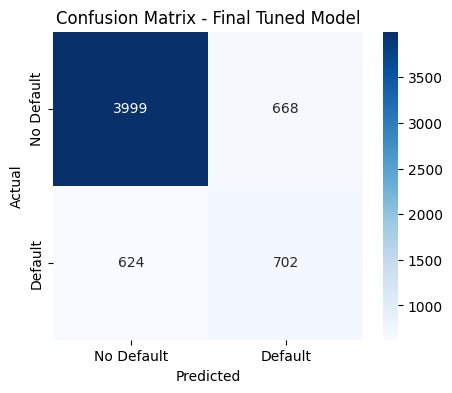

In [13]:
final_pred = (y_proba_final >= best_threshold).astype(int)

print(f"Final tuned model @ optimized threshold ({best_threshold}):")
print(f"  Accuracy:  {accuracy_score(y_test, final_pred):.4f}")
print(f"  Precision: {precision_score(y_test, final_pred):.4f}")
print(f"  Recall:    {recall_score(y_test, final_pred):.4f}")
print(f"  F1:        {f1_score(y_test, final_pred):.4f}")
print(f"  ROC-AUC:   {roc_auc_score(y_test, y_proba_final):.4f}")

cm = confusion_matrix(y_test, final_pred)
import seaborn as sns
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Default","Default"], yticklabels=["No Default","Default"])
plt.title("Confusion Matrix - Final Tuned Model")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()


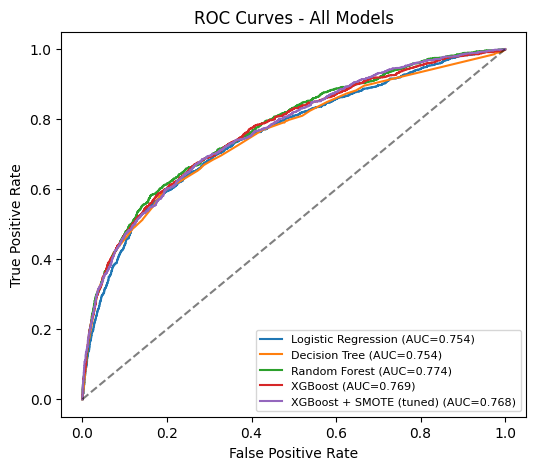

In [14]:
plt.figure(figsize=(6,5))
for name, pipe in {**fitted_pipelines, "XGBoost + SMOTE (tuned)": best_pipeline}.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0,1],[0,1],"k--", alpha=0.5)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend(fontsize=8)
plt.show()


## 8. SHAP explainability

**Global explanation** — what generally drives predictions across all customers.
**Individual explanation** — why did *this specific* customer get flagged as high risk.


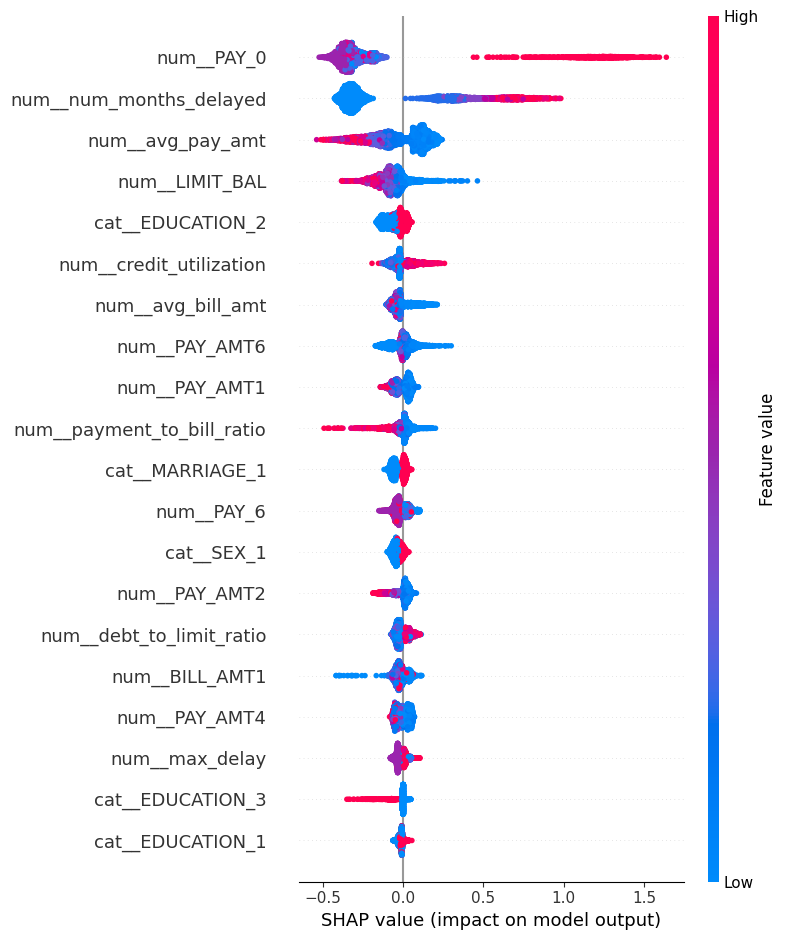

In [15]:
import shap

prep = best_pipeline.named_steps["prep"]
clf = best_pipeline.named_steps["clf"]

X_test_transformed = prep.transform(X_test)
feature_names = prep.get_feature_names_out()
X_test_df = pd.DataFrame(
    X_test_transformed.toarray() if hasattr(X_test_transformed, "toarray") else X_test_transformed,
    columns=feature_names,
)

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X_test_df)

shap.summary_plot(shap_values, X_test_df)


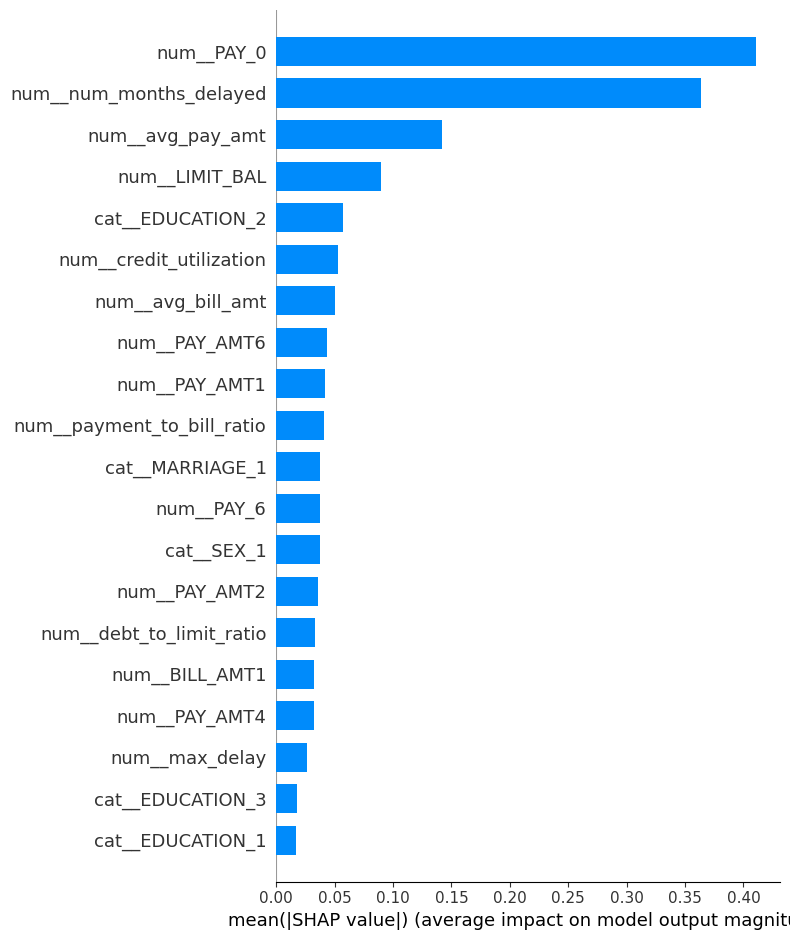

In [16]:
shap.summary_plot(shap_values, X_test_df, plot_type="bar")


Actual label: 0  | Predicted probability: 0.236


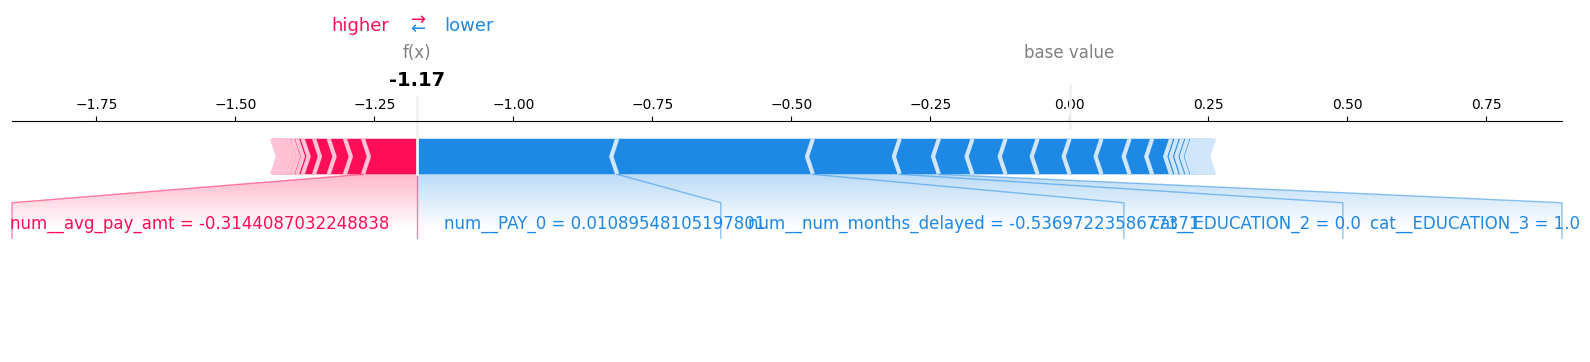

In [17]:
# Individual explanation for one customer (row 0 of the test set)
idx = 0
print("Actual label:", y_test.iloc[idx], " | Predicted probability:", round(y_proba_final[idx], 3))

shap.force_plot(
    explainer.expected_value, shap_values[idx], X_test_df.iloc[idx],
    matplotlib=True, show=True,
)


## 9. Export artifacts for the API / Streamlit app

Save `pipeline.joblib` and `threshold.json` — these are exactly what `src/predict.py`,
`api/main.py`, and `app/streamlit_app.py` in the full project expect, so you can drop them
straight into the `models/` folder of the repo.


In [18]:
import joblib, json

joblib.dump(best_pipeline, "pipeline.joblib")

with open("threshold.json", "w") as f:
    json.dump({"best": {"threshold": best_threshold, "f1": float(best_row['f1'])},
               "sweep": sweep_df.to_dict(orient="records")}, f, indent=2)

with open("metrics.json", "w") as f:
    json.dump({
        "baseline_comparison": comparison_df.reset_index().to_dict(orient="records"),
        "final_tuned_model": {
            "Accuracy": accuracy_score(y_test, final_pred),
            "Precision": precision_score(y_test, final_pred),
            "Recall": recall_score(y_test, final_pred),
            "F1": f1_score(y_test, final_pred),
            "ROC-AUC": roc_auc_score(y_test, y_proba_final),
            "CV_ROC_AUC_mean": float(cv_scores.mean()),
            "CV_ROC_AUC_std": float(cv_scores.std()),
        },
        "best_hyperparameters": search.best_params_,
    }, f, indent=2)

from google.colab import files
files.download("pipeline.joblib")
files.download("threshold.json")
files.download("metrics.json")
print("Artifacts saved and downloaded. Move them into your project's models/ folder.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Artifacts saved and downloaded. Move them into your project's models/ folder.


## 10. What's next

You now have everything the priority table calls "Must": XGBoost, imbalance handling,
full metrics, SHAP, hyperparameter tuning, cross-validation, and a threshold-optimized,
leak-free pipeline. The full production project (FastAPI + Streamlit + Docker + tests +
README) that consumes these exact artifacts is provided alongside this notebook as a
ready-to-run repository (`credit-risk-prediction/`).
